### Build A Basic Chatbot With Langgraph(GRAPH API)

In [1]:
from typing import Annotated
from typing_extensions import TypedDict

from langgraph.graph import StateGraph,START,END
from langgraph.graph.message import add_messages

In [2]:
class State(TypedDict):
    messages:Annotated[list,add_messages]

In [31]:
import os 
from dotenv import load_dotenv
load_dotenv()

True

In [14]:
from langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model

llm = ChatGroq(model="openai/gpt-oss-120b")


In [15]:
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.3', 'langchain': '1.4.7'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000002DB7AA67CE0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000002DB7C59C9D0>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [16]:
llm=init_chat_model("groq:openai/gpt-oss-120b")
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.3', 'langchain': '1.4.7'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000002DB7C57E450>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000002DB7C57ED50>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [26]:
# Node Functionality

def chatbot(state:State):
    print(f"-------------state-{state}")
    return {"messages":[llm.invoke(state["messages"])]}

In [18]:
graph_builder = StateGraph(State)

## Adding node
graph_builder.add_node("llmchatbot",chatbot)
## Adding Edges
graph_builder.add_edge(START,"llmchatbot")
graph_builder.add_edge("llmchatbot",END)

graph = graph_builder.compile()


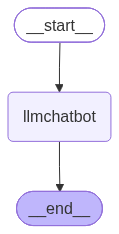

In [19]:
## visualize the graph
from IPython.display import Image,display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [23]:
response=graph.invoke({"messages":"Hi"})

In [25]:
response['messages'][-1].content

'Hello! How can I help you today?'

In [29]:
for event in graph.stream({"messages":"Hi How are you?"}):
    for value in event.values():
        print(value["messages"][-1].content)

Hello! I'm doing great, thank you for asking. How can I help you today?


### chatbot with tool


In [42]:
from langchain_tavily import TavilySearch

tool = TavilySearch(max_results=2)
tool.invoke("what is langgraph")

{'query': 'what is langgraph',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.geeksforgeeks.org/machine-learning/what-is-langgraph',
   'title': 'What is LangGraph - GeeksforGeeks',
   'content': 'LangGraph is an open-source framework from LangChain designed to build and manage AI agent workflows using graph-based structures. It allows developers to define workflows as nodes and edges, making complex agent interactions more structured, scalable and easier to control. [...] langgraph: Framework for building graph-based AI workflows.\n langchain: Popular toolkit for LLM-powered AI applications.\n google-generativeai: Google’s API for Generative AI (Gemini models).\n\n Python  ````\n! pip install langgraph langchain google - generativeai\n```` \n\n### Step 2: Setup Gemini API [...] ## Building a Simple Chatbot with LangGraph\n\nLangGraph makes it easy to build structured, stateful applications like chatbots. In this example we’ll learn how 

In [43]:
## custom function

def multiply(a:int,b:int) -> int:
    """
        Multiply a and b 

        Args:
            a (int): first int
            b (int): second int

        returns:
        int: output int
    """
    return a*b

In [44]:
tools = [tool,multiply]

In [45]:
llm_with_tool = llm.bind_tools(tools)

In [46]:
llm_with_tool

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.3', 'langchain': '1.4.7'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000002DB7C57E450>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000002DB7C57ED50>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for comprehensive, accurate, an

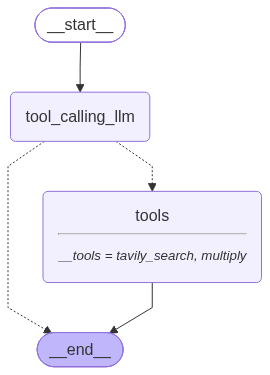

In [56]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Grpah
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools",END)

## compile the graph
graph=builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [57]:
response = graph.invoke({"messages":"What is the recent ai news"})

In [58]:
response['messages'][-1].content

'{"query": "AI news November 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.youtube.com/watch?v=1t0kdeDCHJ0", "title": "Episode 230: Weekly AI News Summary - 2 November 2026", "content": "In today’s Weekly AI News Summary.. Anthropic’s financial disclosures reveal the enormous costs of competing in the AI race, while growing concerns over AI spending, corporate debt and disappointing returns trigger a major selloff in technology stocks. Meanwhile, a US startup is offering people nearly Rs 1,900 per hour to walk robotic dogs for real-world AI training, and Microsoft introduces voluntary buyouts for thousands of employees amid its massive AI investment push. Google faces concerns over its advertising business as AI transforms traditional search, while robotics startup Physical Intelligence reportedly targets a $20 billion valuation. In China, an AI-generated film struggles to attract audiences, and the country\'s stock markets face moun

In [59]:
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is the recent ai news
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_ff95e18b-8aa9-4d40-9bd7-f441fa73d6bf)
 Call ID: fc_ff95e18b-8aa9-4d40-9bd7-f441fa73d6bf
  Args:
    query: AI news November 2026
    search_depth: advanced
    time_range: week
================================= Tool Message =================================
Name: tavily_search

{"query": "AI news November 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.youtube.com/watch?v=1t0kdeDCHJ0", "title": "Episode 230: Weekly AI News Summary - 2 November 2026", "content": "In today’s Weekly AI News Summary.. Anthropic’s financial disclosures reveal the enormous costs of competing in the AI race, while growing concerns over AI spending, corporate debt and disappointing returns trigger a major selloff in technology stocks. Meanwhi

In [63]:
response=graph.invoke({"messages":"What is 53647 multiplied by 73908472"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is 53647 multiplied by 73908472
================================== Ai Message ==================================

\(53{,}647 \times 73{,}908{,}472 = 3{,}964{,}967{,}797{,}384\)


In [65]:
response = graph.invoke({"messages":"mulltiply 5 by 10 and then give me the recent ai news"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

mulltiply 5 by 10 and then give me the recent ai news
================================== Ai Message ==================================
Tool Calls:
  multiply (fc_6e5fc3ac-a3e6-44dc-b165-ae5677d4badf)
 Call ID: fc_6e5fc3ac-a3e6-44dc-b165-ae5677d4badf
  Args:
    a: 5
    b: 10
================================= Tool Message =================================
Name: multiply

50


### ReAct agent Architecture

In [ ]:
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition


def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state['messages'])]}

builder=StateGraph(State)
builder.add_node()
